# Fixed-current gel transport: diffusivity, conductivity and length

This notebook compares how gel properties and total transport length affect drug-proxy transport at **fixed total current**, then filters candidates using a **1.23 V voltage criterion**.

**Default reference:** 0.1 mA, 20 mm² transport cross-section, 10 min forward, 10 min reversal, and 72 h independent passive storage. The final section compares one-at-a-time effects and local sensitivities on a common basis.

The full 882-case default screen is embedded, so the notebook opens with results and runs without external data files. Changing physical settings automatically recomputes the screen. Dependencies: `numpy`, `scipy`, `pandas`, `matplotlib`.

**Voltage breakdown criterion:** flag `V_screen > 1.23 V`; retain `V_screen <= 1.23 V` for the voltage-passing candidate table. This is a user-selected screening criterion, not a simulated breakdown event or proof that a case is electrochemically stable.

**Automatic saving:** with `SAVE_OUTPUTS = True`, every displayed figure is saved as PNG and PDF, every displayed table as CSV and HTML, and named result datasets/settings are exported in the final cell. Each run uses a new timestamped `gel_transport_outputs` folder. Save the notebook itself in Jupyter to retain changed code and its embedded outputs.

## 1. Physical meaning and assumptions

Two equal-length gel regions share a constant cross-section. R is the initially loaded reservoir; G is the initially empty receiver. Positive current drives a positive monovalent tracer toward G.

\[
j=I/A,\qquad E_R=j/\sigma_R,\quad E_G=j/\sigma_G,
\]
\[
R_{gel}=\frac{L_R/\sigma_R+L_G/\sigma_G}{A},\qquad V_{gel}=I R_{gel}.
\]

Tracer flux is diffusion plus electromigration, with electrical mobility tied to diffusivity by the Nernst–Einstein relation. There is no convection, preferential interface partitioning, electrode chemistry or tissue sink. Conductivity is prescribed independently of drug concentration. Closed boundaries and equal volumes give a 50% passive equilibrium receiver inventory.

- **Forward:** +I for 10 min from the initial loading.
- **Reversal:** −I for 10 min, starting from the forward endpoint.
- **Zero-current hold:** 10 min from the same forward endpoint, as the reversal comparator.
- **Passive storage:** 72 h from the original loading, independent of forward stimulation.

Loading concentration stays fixed, so the initial inventory grows with length. A mass fraction and an absolute transferred mass therefore answer different questions.

### Interpreting 1.23 V
1.23 V is the standard reversible water-splitting voltage near 25°C. Actual electrolysis onset and device damage depend on electrodes, kinetics, pH and voltage losses. This transport model does not predict them. `V_gel` excludes electrode/contact losses. You can add a measured extra voltage through `EXTRA_VOLTAGE_V`; zero means those losses are unknown/omitted, not that they vanish.

Reference: [ACS, Introducing PEM Electrolysis with a Transparent Electrolyzer for Hands-on Electrochemistry Education](https://pubs.acs.org/doi/10.1021/acs.jchemed.5c00647).

In [15]:
import io, json, gzip, base64, math
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle

plt.rcParams.update({'font.size': 11, 'axes.titlesize': 14, 'axes.labelsize': 12,
                     'figure.dpi': 120, 'savefig.dpi': 220})
TEAL, PURPLE, ORANGE, GREY, RED = '#00898B', '#7461AA', '#BC7026', '#BCC4CB', '#BA3545'

SAVE_OUTPUTS = True
OUTPUT_DIR = Path.cwd() / 'gel_transport_outputs' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
_figure_number = 0
_table_number = 0

def table(df):
    global _table_number
    _table_number += 1
    html = df.to_html(index=False, float_format=lambda x: f'{x:.4g}')
    if SAVE_OUTPUTS:
        df.to_csv(OUTPUT_DIR / f'table_{_table_number:02d}.csv', index=False)
        (OUTPUT_DIR / f'table_{_table_number:02d}.html').write_text(html, encoding='utf-8')
    display_html(html)

def show_and_save():
    global _figure_number
    figures = [plt.figure(number) for number in plt.get_fignums()]
    for fig in figures:
        _figure_number += 1
        if SAVE_OUTPUTS:
            for ext in ['png', 'pdf']:
                fig.savefig(OUTPUT_DIR / f'figure_{_figure_number:02d}.{ext}',
                            dpi=220, bbox_inches='tight')
    plt.show()
    plt.close('all')

def display_html(html):
    try:
        from IPython.display import display, HTML
        display(HTML(html))
    except ImportError:
        print(html)

print('Dependencies loaded. All input lengths are SI metres inside the solver.')

Dependencies loaded. All input lengths are SI metres inside the solver.


## 2. Transport solver
The following cell embeds the conservative fitted-flux drift/diffusion solver and its numerical checks. It is collapsed by default for readability. Current is imposed directly in the flux operator; it is never clipped to satisfy the voltage criterion.

In [16]:
from pathlib import Path

from dataclasses import dataclass, asdict, replace

from itertools import product

import argparse, csv, json, math, time

from concurrent.futures import ProcessPoolExecutor

import numpy as np

from scipy.linalg import solve_banded

F=96485.33212

R=8.314462618

LENGTHS=[.0005,.001,.002,.005,.010,.020]

D_VALUES=[1e-12,1e-11,1e-10,1.15e-10,1.68e-10,2.33e-10,1e-9]

RATIOS=[.1,1.,10.]

@dataclass
class Settings:
    lengths: tuple=tuple(LENGTHS)
    d_r_values: tuple=tuple(D_VALUES)
    d_g_values: tuple=tuple(D_VALUES)
    sigma_ratios: tuple=tuple(RATIOS)
    sigma_g_values: tuple=(.1,)
    currents_A: tuple=(0.0001,)
    reservoir_fraction: float=.5
    area_m2: float=20e-6  # mini setup: 20 mm x 1 mm transport cross-section
    loading_kg_m3: float=5.9
    temperature_K: float=293.15
    charge: float=1.
    forward_s: float=600.
    reverse_s: float=600.
    storage_hours: float=72.
    dt_s: float=2.
    storage_dt_s: float=120.
    cells_per_gel: int=200
    min_forward_fraction: object=None
    min_net_return_fraction: object=None
    max_storage_leakage_fraction: object=None
    min_forward_mass_ug: object=None
    max_voltage_V: object=None  # assessment only, never clips ideal current
    mass_tolerance: float=1e-7
    refine_count: int=8

def validate_settings(s):
    for values in [s.lengths,s.d_r_values,s.d_g_values,s.sigma_ratios,s.sigma_g_values,s.currents_A]:
        if not values or any(not np.isfinite(v) or v<=0 for v in values):raise ValueError('Sweep entries must be finite and positive')
    if not 0<s.reservoir_fraction<1:raise ValueError('Reservoir fraction must be in (0,1)')
    if s.charge<=0:raise ValueError('This forward-polarity convention requires positive charge')
    if s.cells_per_gel<20:raise ValueError('Use at least 20 cells per gel')
    for v in [s.area_m2,s.loading_kg_m3,s.temperature_K,s.forward_s,s.reverse_s,s.storage_hours,s.dt_s,s.storage_dt_s]:
        if not np.isfinite(v) or v<=0:raise ValueError('Physical inputs and time steps must be positive')
    for name in ['min_forward_fraction','min_net_return_fraction','max_storage_leakage_fraction']:
        v=getattr(s,name)
        if v is not None and not 0<=v<=1:raise ValueError(name+' must be in [0,1] or null')
    for name in ['min_forward_mass_ug','max_voltage_V']:
        v=getattr(s,name)
        if v is not None and (not np.isfinite(v) or v<=0):raise ValueError(name+' must be positive or null')

def grid(length,dr,dg,sr,sg,s):
    lr=length*s.reservoir_fraction;lg=length-lr;n=s.cells_per_gel
    # Cosine-spaced cells cluster at electrode ends and at the gel interface.
    # Every interface is exactly aligned even when LR != LG.
    u=(1-np.cos(np.linspace(0,np.pi,n+1)))/2
    edges=np.r_[lr*u,lr+lg*u[1:]];dx=np.diff(edges);x=(edges[:-1]+edges[1:])/2
    return x,dx,np.r_[np.full(n,dr),np.full(n,dg)],np.r_[np.full(n,sr),np.full(n,sg)]

def exprel(p):
    out=np.empty_like(p);small=np.abs(p)<1e-5
    out[small]=1+p[small]/2+p[small]**2/6+p[small]**3/24
    out[~small]=np.expm1(p[~small])/p[~small]
    return out

def band_operator(dx,d,sigma,current_A,dt,s):
    # Imposed constant total current. j and E are independent of total length
    # at fixed cross-section and local conductivity. No voltage clipping.
    je=current_A/s.area_m2
    p=s.charge*F/(R*s.temperature_K)*(je/sigma)*dx/2
    # Exact fitted flux across two half-cells. Unlike averaging mobility,
    # this explicitly handles a D AND conductivity jump at the interface.
    denominator=dx[:-1]/(2*d[:-1])*exprel(p[:-1])*np.exp(p[1:])+dx[1:]/(2*d[1:])*exprel(p[1:])
    a=np.exp(p[:-1]+p[1:])/denominator;b=1/denominator
    diag=np.zeros(len(dx));diag[:-1]+=a/dx[:-1];diag[1:]+=b/dx[1:]
    ab=np.zeros((3,len(dx)));ab[1]=1+dt*diag
    ab[0,1:]=-dt*b/dx[:-1];ab[2,:-1]=-dt*a/dx[1:]
    return ab

def inventory(c,dx,s):
    n=s.cells_per_gel;m0=s.loading_kg_m3*s.area_m2*np.sum(dx[:n])
    return np.dot(c[n:],dx[n:])*s.area_m2/m0,(np.dot(c,dx)*s.area_m2-m0)/m0

def evolve(c,dx,d,sigma,current_A,duration,dt,s,threshold=None,history=False):
    steps=int(math.ceil(duration/dt));dt=duration/steps
    ab=band_operator(dx,d,sigma,current_A,dt,s)
    initial,err=inventory(c,dx,s);worst=abs(err);minimum=float(c.min())
    t_hit=0. if threshold is not None and initial>=threshold else float('nan');rows=[]
    for k in range(steps+1):
        if history and (k==0 or k==steps or k%max(1,round(10/dt))==0):
            frac,err=inventory(c,dx,s);rows.append(dict(time_s=k*dt,receiver_fraction=frac,relative_mass_error=err))
        if k==steps:break
        c=solve_banded((1,1),ab,c,check_finite=False)
        frac,err=inventory(c,dx,s);worst=max(worst,abs(err));minimum=min(minimum,float(c.min()))
        if threshold is not None and np.isnan(t_hit) and frac>=threshold:t_hit=(k+1)*dt
    return c,dict(worst_mass_error=worst,min_concentration=minimum,t_hit_s=t_hit),rows

def passive(length,dr,dg,s):
    x,dx,d,sigma=grid(length,dr,dg,.1,.1,s)
    c0=np.r_[np.full(s.cells_per_gel,s.loading_kg_m3),np.zeros(s.cells_per_gel)]
    off,a,_=evolve(c0.copy(),dx,d,sigma,0,s.forward_s,s.dt_s,s)
    storage,b,_=evolve(c0.copy(),dx,d,sigma,0,s.storage_hours*3600,s.storage_dt_s,s)
    return inventory(off,dx,s)[0],inventory(storage,dx,s)[0],max(a['worst_mass_error'],b['worst_mass_error']),min(a['min_concentration'],b['min_concentration'])

def classify(row,s):
    if row.get('refinement_status')=='NEEDS_REFINEMENT':return 'NEEDS_REFINEMENT'
    if row['worst_mass_error']>s.mass_tolerance:return 'NUMERICAL_CHECK_FAILED'
    if row['min_concentration_kg_m3'] < -s.loading_kg_m3*1e-8:return 'NEGATIVE_CONCENTRATION'
    limits=[s.min_forward_fraction,s.min_net_return_fraction,s.max_storage_leakage_fraction]
    if any(v is None for v in limits):return 'TARGETS_NOT_SPECIFIED'
    ok=row['forward_fraction']>=s.min_forward_fraction and row['net_return_fraction_of_forward']>=s.min_net_return_fraction and row['storage_leakage_fraction']<=s.max_storage_leakage_fraction
    if s.min_forward_mass_ug is not None:ok &= row['forward_mass_ug']>=s.min_forward_mass_ug
    if s.max_voltage_V is not None:ok &= row['voltage_V']<=s.max_voltage_V
    return 'MEETS_LIMITS_ON_SCREEN_GRID' if ok else 'OUTSIDE_LIMITS'

def run_case(length,dr,dg,ratio,sg,current_A,s,passive_result=None,history=False):
    sr=ratio*sg;x,dx,d,sigma=grid(length,dr,dg,sr,sg,s)
    c0=np.r_[np.full(s.cells_per_gel,s.loading_kg_m3),np.zeros(s.cells_per_gel)]
    on,a,h1=evolve(c0.copy(),dx,d,sigma,current_A,s.forward_s,s.dt_s,s,s.min_forward_fraction,history)
    rev,b,h2=evolve(on.copy(),dx,d,sigma,-current_A,s.reverse_s,s.dt_s,s,history=history)
    hold,h,h3=evolve(on.copy(),dx,d,sigma,0,s.reverse_s,s.dt_s,s,history=history)
    p,store,pmass,pmin=passive_result if passive_result is not None else passive(length,dr,dg,s)
    fw=inventory(on,dx,s)[0];back=inventory(rev,dx,s)[0];held=inventory(hold,dx,s)[0]
    lr=length*s.reservoir_fraction;lg=length-lr;m0=s.loading_kg_m3*s.area_m2*lr
    resistance=(lr/sr+lg/sg)/s.area_m2;je=current_A/s.area_m2;v=current_A*resistance
    row=dict(total_length_m=length,LR_m=lr,LG_m=lg,D_R_m2_s=dr,D_G_m2_s=dg,sigma_ratio=ratio,sigma_R_S_m=sr,sigma_G_S_m=sg,voltage_V=v,control_mode="fixed_total_current",area_m2=s.area_m2,
             E_R_V_m=je/sr,E_G_V_m=je/sg,voltage_fraction_R=(lr/sr)/(lr/sr+lg/sg),R_gel_ohm=resistance,current_A=current_A,
             power_W=current_A*v,energy_forward_J=current_A*v*s.forward_s,initial_mass_ug=m0*1e9,
             forward_fraction=fw,forward_mass_ug=fw*m0*1e9,passive_fraction_10min=p,active_gain_fraction=fw-p,
             active_to_passive_ratio=fw/p if p>0 else float('nan'),reverse_final_fraction=back,hold_final_fraction=held,
             net_return_fraction_of_forward=(fw-back)/fw if fw>1e-15 else float('nan'),
             reversal_benefit_vs_hold=(held-back)/fw if fw>1e-15 else float('nan'),storage_hours=s.storage_hours,storage_leakage_fraction=store,
             time_to_forward_target_s=a['t_hit_s'],worst_mass_error=max(a['worst_mass_error'],b['worst_mass_error'],h['worst_mass_error'],pmass),
             min_concentration_kg_m3=min(a['min_concentration'],b['min_concentration'],h['min_concentration'],pmin),
             cells_total=2*s.cells_per_gel,dt_s=s.dt_s,refinement_status='NOT_CHECKED')
    row['within_voltage_limit']=s.max_voltage_V is None or v<=s.max_voltage_V
    row['feasibility']=classify(row,s)
    return row,dict(x=x,initial=c0,forward=on,reverse=rev,hold=hold,histories=[h1,h2,h3])

def write_csv(path,rows,fields=None):
    with Path(path).open('w',newline='') as f:
        w=csv.DictWriter(f,fieldnames=fields or list(rows[0]) if rows else fields or ['no_rows'])
        w.writeheader();w.writerows(rows)

def validate_numerics(s):
    fine=replace(s,cells_per_gel=250,dt_s=1.,storage_dt_s=120.)
    # Independent early-time diffusion solution, unaffected by drive convention.
    off,_,err,minimum=passive(.040,1.68e-10,1.68e-10,fine)
    analytic=math.sqrt(1.68e-10*600/math.pi)/.020
    i=fine.currents_A[0]
    cases=[run_case(L,1e-10,1e-10,1.,.1,i,fine)[0] for L in [.0005,.002,.020]]
    # Stationary zero-flux drift/diffusion equilibrium with discontinuous sigma and D.
    x,dx,d,sigma=grid(.002,1e-10,2e-10,.01,.1,fine)
    phi=s.charge*F/(R*s.temperature_K)*(i/s.area_m2)*(np.cumsum(dx/sigma)-dx/(2*sigma))
    equilibrium=np.exp(phi-phi.max())
    equilibrium*=s.loading_kg_m3*np.sum(dx[:fine.cells_per_gel])/np.dot(equilibrium,dx)
    stepped=solve_banded((1,1),band_operator(dx,d,sigma,i,1.,fine),equilibrium)
    stationary=float(np.max(abs(stepped-equilibrium))/equilibrium.max())
    # Uniform concentration must have zero change at zero current.
    uniform=np.ones(len(dx));still=solve_banded((1,1),band_operator(dx,d,sigma,0,1.,fine),uniform)
    # Reversing current reverses signed E and the off-diagonal directional flux bias.
    opplus=band_operator(dx,d,sigma,i,1.,fine);opminus=band_operator(dx,d,sigma,-i,1.,fine)
    assert not np.allclose(opplus,opminus)
    current_error=max(abs(r['current_A']-i) for r in cases)
    voltage_error=max(abs(r['voltage_V']-i*r['total_length_m']/(.1*s.area_m2)) for r in cases)
    field_span=float(np.ptp([r['E_R_V_m'] for r in cases]))
    result=dict(passive_relative_error=abs(off/analytic-1),passive_mass_error=err,
                constant_current_error_A=current_error,series_voltage_error_V=voltage_error,
                uniform_field_span_across_lengths_V_m=field_span,
                stationary_equilibrium_relative_error=stationary,
                zero_drive_uniform_error=float(np.max(abs(still-uniform))),
                case_mass_error=max(r['worst_mass_error'] for r in cases))
    assert result['passive_relative_error']<.005
    assert current_error<1e-15 and voltage_error<1e-12 and field_span<1e-12
    assert stationary<1e-8 and result['zero_drive_uniform_error']<1e-8
    assert result['case_mass_error']<s.mass_tolerance and minimum>=0
    return result

def solve_group(args):
    length,dr,dg,s=args
    pa=passive(length,dr,dg,s)
    return [run_case(length,dr,dg,ratio,sg,i,s,pa)[0]
            for ratio,sg,i in product(s.sigma_ratios,s.sigma_g_values,s.currents_A)]

def refine_rows(rows,s):
    selected=[]
    # Each length: a representative transition case plus extrema in the screen.
    for L in s.lengths:
        group=[r for r in rows if r['total_length_m']==L]
        selected.append(min(group,key=lambda r:abs(r['forward_fraction']-.5)))
    selected += [max(rows,key=lambda r:r['forward_fraction']),min(rows,key=lambda r:r['forward_fraction']),
                 max(rows,key=lambda r:r['voltage_V']),max(rows,key=lambda r:abs(r['net_return_fraction_of_forward']))]
    keys=['total_length_m','D_R_m2_s','D_G_m2_s','sigma_ratio','sigma_G_S_m','current_A']
    checks=[];seen=set();fine=replace(s,cells_per_gel=s.cells_per_gel*2,dt_s=s.dt_s/4,storage_dt_s=s.storage_dt_s/4)
    for row in selected:
        key=tuple(row[k] for k in keys)
        if key in seen:continue
        seen.add(key);refined,_=run_case(*key,fine)
        differences={k:abs(row[k]-refined[k]) for k in ['forward_fraction','net_return_fraction_of_forward','storage_leakage_fraction']}
        passed=max(differences.values())<.005
        row['refinement_status']='PASS_ABSOLUTE_0p005' if passed else 'NEEDS_REFINEMENT'
        row['feasibility']=classify(row,s)
        checks.append(dict(zip(keys,key),**differences,passed=passed))
    return checks

## 3. Editable settings
Change this cell and run all cells again. Keep current and cross-section consistent with the experiment. `VOLTAGE_LIMIT_V` changes screening only; it does not change the ideal imposed current. The optional extra voltage affects screening, not the gel field calculation.

In [17]:
CURRENT_mA = 0.1
AREA_mm2 = 20.0
VOLTAGE_LIMIT_V = 1.23
EXTRA_VOLTAGE_V = 0.0  # optional measured electrode/contact contribution
FORCE_RECOMPUTE = False

LENGTHS_mm = [0.5, 1, 2, 5, 10, 20]
DIFFUSIVITIES = [1e-12, 1e-11, 1e-10, 1.15e-10, 1.68e-10, 2.33e-10, 1e-9]
CONDUCTIVITY_RATIOS = [0.1, 1.0, 10.0]
SIGMA_G_S_m = 0.1

BASE_LENGTH_mm = 2.0
BASE_D_R = 1e-10
BASE_D_G = 1e-10
BASE_SIGMA_R = 0.1
BASE_SIGMA_G = 0.1
LOCAL_CHANGE = 0.10  # common +/-10% change for fair local sensitivity comparison

assert CURRENT_mA > 0 and AREA_mm2 > 0
assert VOLTAGE_LIMIT_V > 0 and EXTRA_VOLTAGE_V >= 0
assert 0 < LOCAL_CHANGE < 1
s = Settings(lengths=tuple(np.asarray(LENGTHS_mm)*1e-3),
             d_r_values=tuple(DIFFUSIVITIES), d_g_values=tuple(DIFFUSIVITIES),
             sigma_ratios=tuple(CONDUCTIVITY_RATIOS), sigma_g_values=(SIGMA_G_S_m,),
             currents_A=(CURRENT_mA*1e-3,), area_m2=AREA_mm2*1e-6,
             max_voltage_V=VOLTAGE_LIMIT_V)
validate_settings(s)
print(f'Fixed current: {CURRENT_mA:g} mA; area: {AREA_mm2:g} mm²; j = {s.currents_A[0]/s.area_m2:g} A/m²')
print(f'Voltage criterion: reject V_screen > {VOLTAGE_LIMIT_V:g} V (no current clipping).')

Fixed current: 0.1 mA; area: 20 mm²; j = 5 A/m²
Voltage criterion: reject V_screen > 1.23 V (no current clipping).


In [18]:
def with_criterion(frame):
    frame = frame.copy()
    frame['V_screen_V'] = frame['voltage_V'] + EXTRA_VOLTAGE_V
    frame['voltage_margin_V'] = VOLTAGE_LIMIT_V - frame['V_screen_V']
    frame['voltage_pass'] = frame['V_screen_V'] <= VOLTAGE_LIMIT_V
    frame['voltage_status'] = np.where(frame.voltage_pass,
                                      'WITHIN_VOLTAGE_CRITERION', 'ABOVE_VOLTAGE_CRITERION')
    frame['forward_pct'] = 100*frame['forward_fraction']
    frame['passive_72h_pct'] = 100*frame['storage_leakage_fraction']
    frame['net_return_pct'] = 100*frame['net_return_fraction_of_forward']
    return frame

def evaluate(L_mm=BASE_LENGTH_mm, DR=BASE_D_R, DG=BASE_D_G,
             sigma_R=BASE_SIGMA_R, sigma_G=BASE_SIGMA_G):
    row, _ = run_case(float(L_mm)*1e-3, float(DR), float(DG),
                      float(sigma_R/sigma_G), float(sigma_G), s.currents_A[0], s)
    return with_criterion(pd.DataFrame([row])).iloc[0].to_dict()

checks = validate_numerics(s)
assert max(abs(v) for k,v in checks.items() if k in ['constant_current_error_A',
    'series_voltage_error_V','uniform_field_span_across_lengths_V_m']) < 1e-10
table(pd.DataFrame({'check': list(checks), 'value': list(checks.values())}))
baseline = evaluate()
print('Reference case:')
table(pd.DataFrame([{k: baseline[k] for k in ['total_length_m','current_A','voltage_V',
      'V_screen_V','forward_pct','passive_72h_pct','initial_mass_ug','forward_mass_ug','voltage_status']}]))

check,value
passive_relative_error,0.0007492
passive_mass_error,3.315e-13
constant_current_error_A,0
series_voltage_error_V,2.22e-16
uniform_field_span_across_lengths_V_m,0
stationary_equilibrium_relative_error,1.119e-14
zero_drive_uniform_error,5.773e-14
case_mass_error,1.001e-09


Reference case:


total_length_m,current_A,voltage_V,V_screen_V,forward_pct,passive_72h_pct,initial_mass_ug,forward_mass_ug,voltage_status
0.002,0.0001,0.1,0.1,20.54,50,118,24.23,WITHIN_VOLTAGE_CRITERION


## 4. Full screen and voltage classification
The cache contains the original fixed-current results. Physical settings are checked before reuse. A changed physical configuration triggers a fresh calculation. Cached voltage flags are always replaced using the current criterion. Numerical checks cover selected conditions; they do not validate every physical assumption or establish complete convergence across the entire sweep.

In [19]:
CACHE_SETTINGS = {'lengths': [0.0005, 0.001, 0.002, 0.005, 0.01, 0.02], 'd_r_values': [1e-12, 1e-11, 1e-10, 1.15e-10, 1.68e-10, 2.33e-10, 1e-09], 'd_g_values': [1e-12, 1e-11, 1e-10, 1.15e-10, 1.68e-10, 2.33e-10, 1e-09], 'sigma_ratios': [0.1, 1.0, 10.0], 'sigma_g_values': [0.1], 'currents_A': [0.0001], 'reservoir_fraction': 0.5, 'area_m2': 2e-05, 'loading_kg_m3': 5.9, 'temperature_K': 293.15, 'charge': 1.0, 'forward_s': 600.0, 'reverse_s': 600.0, 'storage_hours': 72.0, 'dt_s': 2.0, 'storage_dt_s': 120.0, 'cells_per_gel': 200, 'min_forward_fraction': None, 'min_net_return_fraction': None, 'max_storage_leakage_fraction': None, 'min_forward_mass_ug': None, 'max_voltage_V': None, 'mass_tolerance': 1e-07, 'refine_count': 8}
PHYSICS_KEYS = ['lengths', 'd_r_values', 'd_g_values', 'sigma_ratios', 'sigma_g_values', 'currents_A', 'reservoir_fraction', 'area_m2', 'loading_kg_m3', 'temperature_K', 'charge', 'forward_s', 'reverse_s', 'storage_hours', 'dt_s', 'storage_dt_s', 'cells_per_gel']
CACHE_GZIP_BASE64 = '...'

def normalized_physics(obj):
    def canonical(value):
        if isinstance(value, (list, tuple)):
            return [canonical(v) for v in value]
        if isinstance(value, (float, np.floating)):
            return float(f'{value:.12g}')
        return value
    return json.dumps({k: canonical(obj[k]) for k in PHYSICS_KEYS}, sort_keys=True)

cache_matches = normalized_physics(asdict(s)) == normalized_physics(CACHE_SETTINGS)
if cache_matches and not FORCE_RECOMPUTE:
    df = pd.read_csv(io.StringIO(gzip.decompress(base64.b64decode(CACHE_GZIP_BASE64)).decode()))
    print('Loaded 882 embedded fixed-current cases: physical settings match.')
else:
    rows = []
    groups = list(product(s.lengths, s.d_r_values, s.d_g_values))
    print(f'Recomputing {len(groups)} transport-property groups; this can take a few minutes.')
    for k, (L, DR, DG) in enumerate(groups):
        pa = passive(L, DR, DG, s)
        for ratio, sigma_G, imposed in product(s.sigma_ratios, s.sigma_g_values, s.currents_A):
            row, _ = run_case(L, DR, DG, ratio, sigma_G, imposed, s, pa)
            rows.append(row)
        if (k+1)%50 == 0: print(f'{k+1}/{len(groups)} groups complete')
    df = pd.DataFrame(rows)
df = with_criterion(df)
assert np.allclose(df.current_A, s.currents_A[0], rtol=0, atol=1e-15)
assert (df.min_concentration_kg_m3 >= -1e-8*s.loading_kg_m3).all()
assert (df.worst_mass_error < s.mass_tolerance).all()
passing = df[df.voltage_pass].copy()
summary = pd.DataFrame({'Metric': ['Cases', 'Within voltage criterion', 'Above voltage criterion',
                                  'Minimum V_screen (V)', 'Maximum V_screen (V)'],
                        'Value': [len(df), int(df.voltage_pass.sum()), int((~df.voltage_pass).sum()),
                                  df.V_screen_V.min(), df.V_screen_V.max()]})
table(summary)
print('Passing the voltage criterion alone does not establish adequate dose, storage retention or device stability.')

Loaded 882 embedded fixed-current cases: physical settings match.


Metric,Value
Cases,882
Within voltage criterion,735
Above voltage criterion,147
Minimum V_screen (V),0.01375
Maximum V_screen (V),5.5


Passing the voltage criterion alone does not establish adequate dose, storage retention or device stability.


## 5. Length: current stays fixed, required voltage changes
At fixed current and cross-section, each gel field is set by its conductivity rather than the total length. A shorter reservoir contains less drug. The fraction transferred and absolute transferred mass must therefore be read separately.

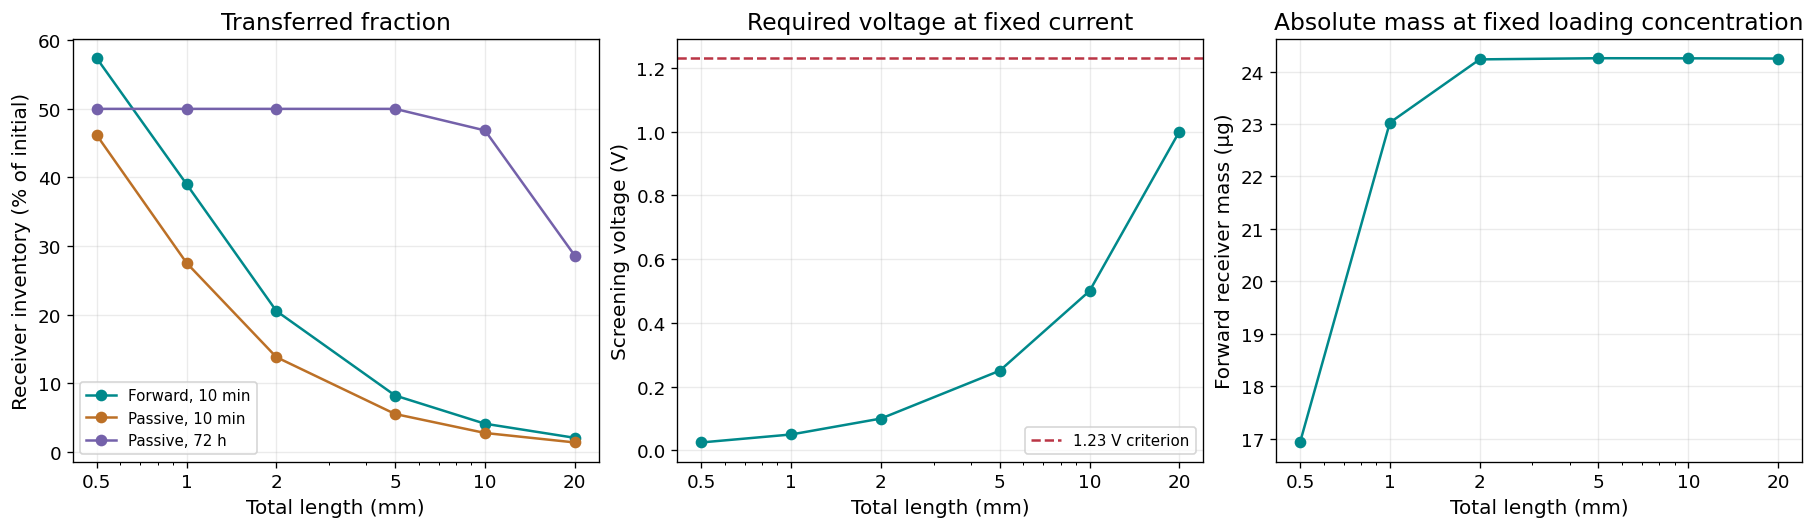

length_mm,current_A,V_screen_V,forward_pct,forward_mass_ug,voltage_status
0.5,0.0001,0.025,57.38,16.93,WITHIN_VOLTAGE_CRITERION
1,0.0001,0.05,39.03,23.03,WITHIN_VOLTAGE_CRITERION
2,0.0001,0.1,20.54,24.23,WITHIN_VOLTAGE_CRITERION
5,0.0001,0.25,8.222,24.26,WITHIN_VOLTAGE_CRITERION
10,0.0001,0.5,4.111,24.25,WITHIN_VOLTAGE_CRITERION
20,0.0001,1,2.055,24.25,WITHIN_VOLTAGE_CRITERION


In [20]:
length_df = pd.DataFrame([evaluate(L_mm=L) for L in LENGTHS_mm])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)
L = length_df.total_length_m*1000
for key, label, col in [('forward_pct','Forward, 10 min',TEAL),
                         ('passive_fraction_10min','Passive, 10 min',ORANGE),
                         ('passive_72h_pct','Passive, 72 h',PURPLE)]:
    values = length_df[key] * (100 if key=='passive_fraction_10min' else 1)
    axes[0].plot(L, values, '-o', label=label, color=col)
axes[0].set(ylabel='Receiver inventory (% of initial)', title='Transferred fraction')
axes[0].legend(fontsize=9)
axes[1].plot(L, length_df.V_screen_V, '-o', color=TEAL)
axes[1].axhline(VOLTAGE_LIMIT_V, color=RED, ls='--', label=f'{VOLTAGE_LIMIT_V:g} V criterion')
axes[1].set(ylabel='Screening voltage (V)', title='Required voltage at fixed current'); axes[1].legend(fontsize=9)
axes[2].plot(L, length_df.forward_mass_ug, '-o', color=TEAL)
axes[2].set(ylabel='Forward receiver mass (µg)', title='Absolute mass at fixed loading concentration')
for ax in axes:
    ax.set_xscale('log'); ax.set_xticks(L, labels=[f'{x:g}' for x in L]); ax.set_xlabel('Total length (mm)'); ax.grid(alpha=.25)
show_and_save()
table(length_df.assign(length_mm=L)[['length_mm','current_A','V_screen_V','forward_pct','forward_mass_ug','voltage_status']])

## 6. Diffusivity: independent effects in reservoir and receiver
The left panel measures 10 min forward transfer. The right measures 72 h passive redistribution from the original loading. Changing D also changes mobility under the model's Nernst–Einstein assumption. Both conductivities, current and total length stay fixed in these maps.

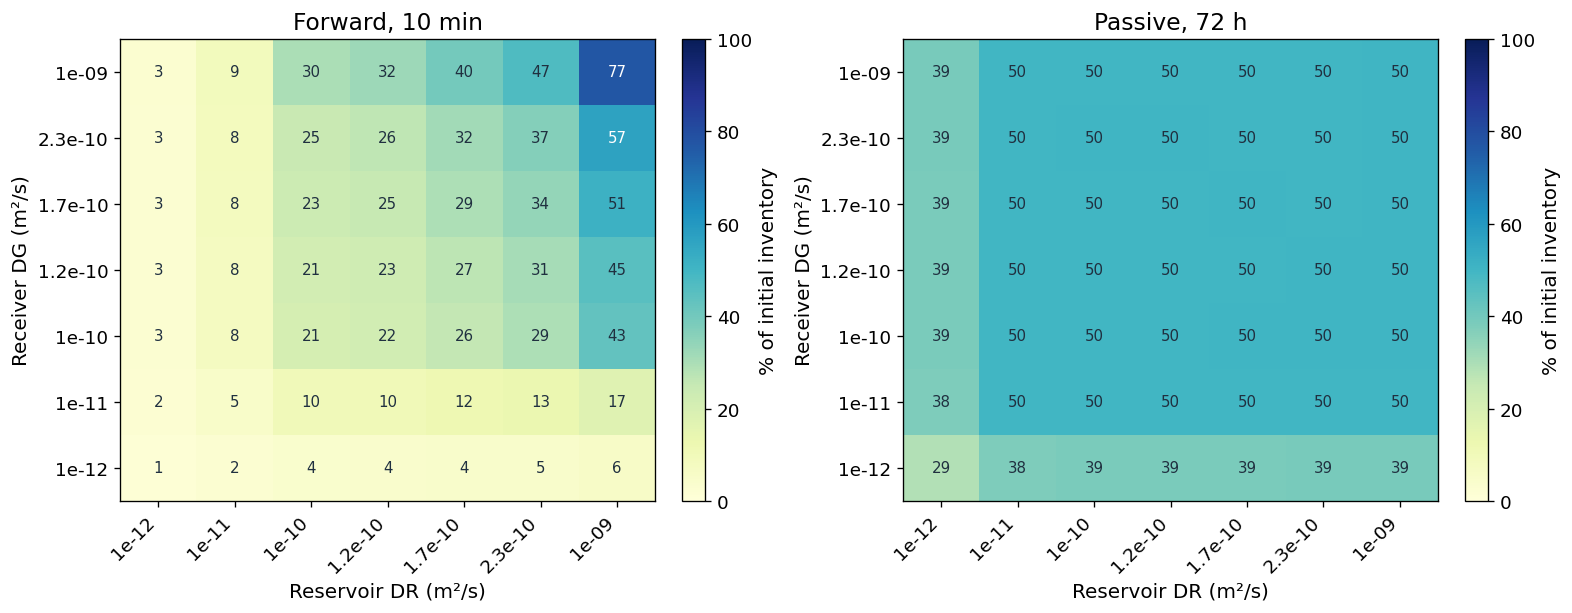

All entries in these maps have the same voltage because conductivity and geometry are fixed.
Map voltage: 0.1 V; criterion: 1.23 V


In [21]:
diff_rows = [evaluate(DR=DR, DG=DG) for DG in DIFFUSIVITIES for DR in DIFFUSIVITIES]
diff_df = pd.DataFrame(diff_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, key, title in zip(axes, ['forward_pct','passive_72h_pct'], ['Forward, 10 min','Passive, 72 h']):
    mat = diff_df[key].to_numpy().reshape(len(DIFFUSIVITIES), len(DIFFUSIVITIES))
    im = ax.imshow(mat, origin='lower', aspect='auto', cmap='YlGnBu', vmin=0, vmax=100)
    ax.set_xticks(range(len(DIFFUSIVITIES)), labels=[f'{x:.2g}' for x in DIFFUSIVITIES], rotation=45, ha='right')
    ax.set_yticks(range(len(DIFFUSIVITIES)), labels=[f'{x:.2g}' for x in DIFFUSIVITIES])
    ax.set(xlabel='Reservoir DR (m²/s)', ylabel='Receiver DG (m²/s)', title=title)
    for y in range(len(DIFFUSIVITIES)):
        for x in range(len(DIFFUSIVITIES)):
            ax.text(x,y,f'{mat[y,x]:.0f}',ha='center',va='center',color='white' if mat[y,x]>55 else '#203040',fontsize=9)
    fig.colorbar(im, ax=ax, label='% of initial inventory')
show_and_save()
print('All entries in these maps have the same voltage because conductivity and geometry are fixed.')
print('Map voltage:', round(diff_df.V_screen_V.iloc[0],4), 'V; criterion:', VOLTAGE_LIMIT_V, 'V')

## 7. Conductivity: absolute values matter at fixed current
The first comparison changes reservoir conductivity while receiver conductivity stays fixed. The second changes both conductivities by the same factor. A conductivity ratio alone is insufficient to define the field under fixed-current operation.

At fixed I and A, increasing sigma_R lowers E_R and its absolute voltage drop. Increasing both conductivities lowers both gel fields and the required voltage.

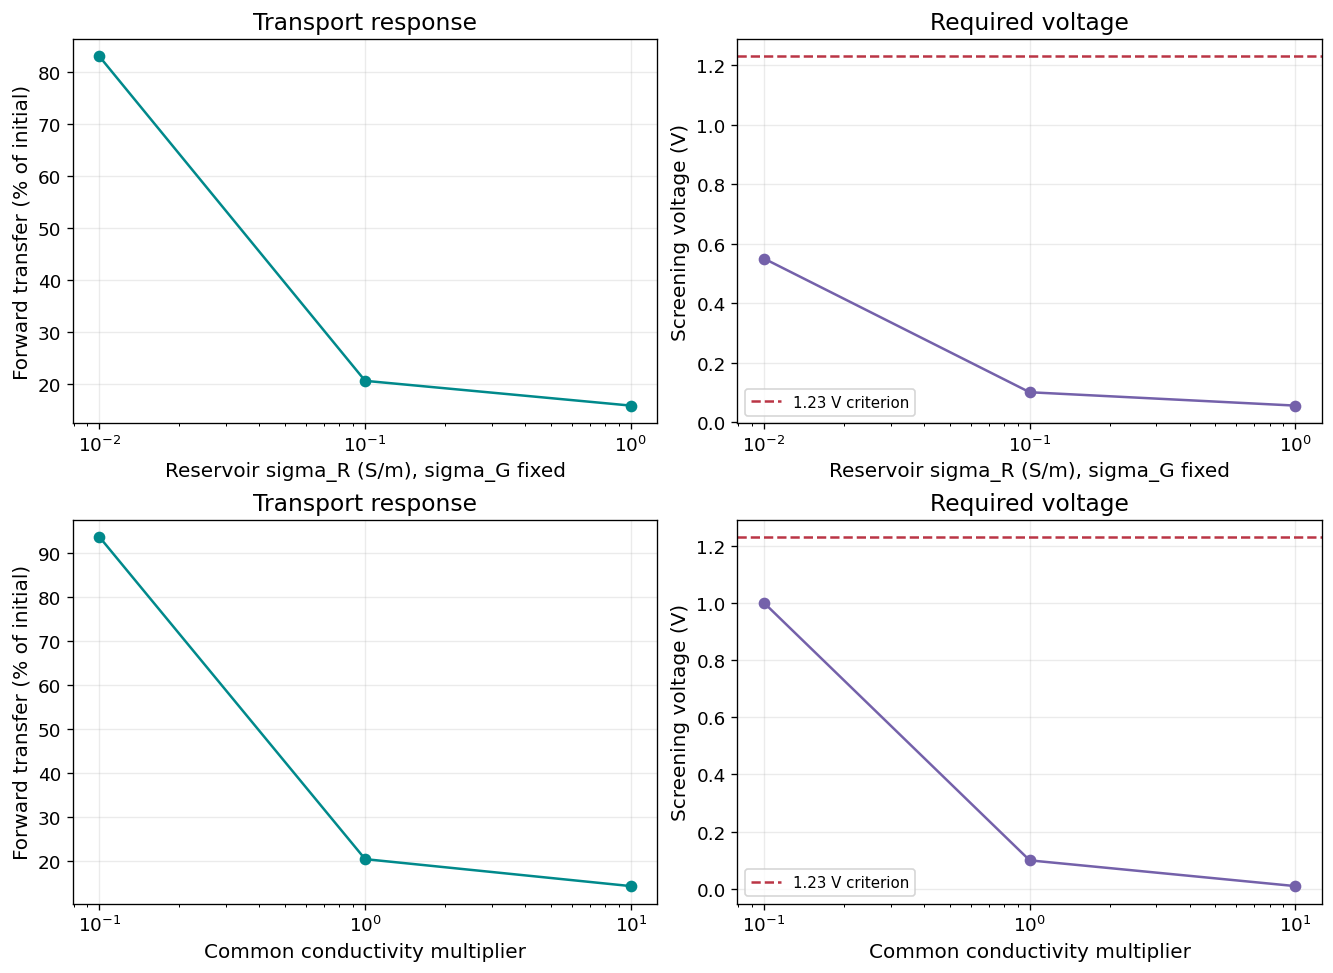

Reservoir-only conductivity sweep:


sigma_R_S_m,sigma_G_S_m,E_R_V_m,E_G_V_m,V_screen_V,forward_pct,voltage_status
0.01,0.1,500,50,0.55,83.01,WITHIN_VOLTAGE_CRITERION
0.1,0.1,50,50,0.1,20.54,WITHIN_VOLTAGE_CRITERION
1,0.1,5,50,0.055,15.76,WITHIN_VOLTAGE_CRITERION


In [22]:
sigma_levels = BASE_SIGMA_R*np.array([0.1, 1, 10])
reservoir_sigma = pd.DataFrame([evaluate(sigma_R=v) for v in sigma_levels])
common_sigma = pd.DataFrame([evaluate(sigma_R=BASE_SIGMA_R*f, sigma_G=BASE_SIGMA_G*f) for f in [0.1,1,10]])
fig, axes = plt.subplots(2,2,figsize=(11,8),constrained_layout=True)
for row, frame, xvals, label in [(0,reservoir_sigma,sigma_levels,'Reservoir sigma_R (S/m), sigma_G fixed'),
                                  (1,common_sigma,np.array([.1,1,10]),'Common conductivity multiplier')]:
    axes[row,0].plot(xvals,frame.forward_pct,'-o',color=TEAL)
    axes[row,0].set(ylabel='Forward transfer (% of initial)',title='Transport response')
    axes[row,1].plot(xvals,frame.V_screen_V,'-o',color=PURPLE)
    axes[row,1].axhline(VOLTAGE_LIMIT_V,color=RED,ls='--',label=f'{VOLTAGE_LIMIT_V:g} V criterion')
    axes[row,1].set(ylabel='Screening voltage (V)',title='Required voltage');axes[row,1].legend(fontsize=9)
    for ax in axes[row]: ax.set_xscale('log');ax.set_xlabel(label);ax.grid(alpha=.25)
show_and_save()
print('Reservoir-only conductivity sweep:')
table(reservoir_sigma[['sigma_R_S_m','sigma_G_S_m','E_R_V_m','E_G_V_m','V_screen_V','forward_pct','voltage_status']])

## 8. Applying the 1.23 V criterion
Cases above the criterion remain visible, but are removed from the voltage-passing candidate set. The ideal-current calculation is not replaced by a lower-current simulation.

For fixed reservoir fraction f and a constant optional extra voltage:
\[
L_{max}=\frac{(V_{limit}-V_{extra})A}{I[f/\sigma_R+(1-f)/\sigma_G]}.
\]
This is an analytical **voltage-only length bound** for the model, not a transport or fabrication optimum. Diffusivity does not enter it because conductivity is prescribed independently of D.

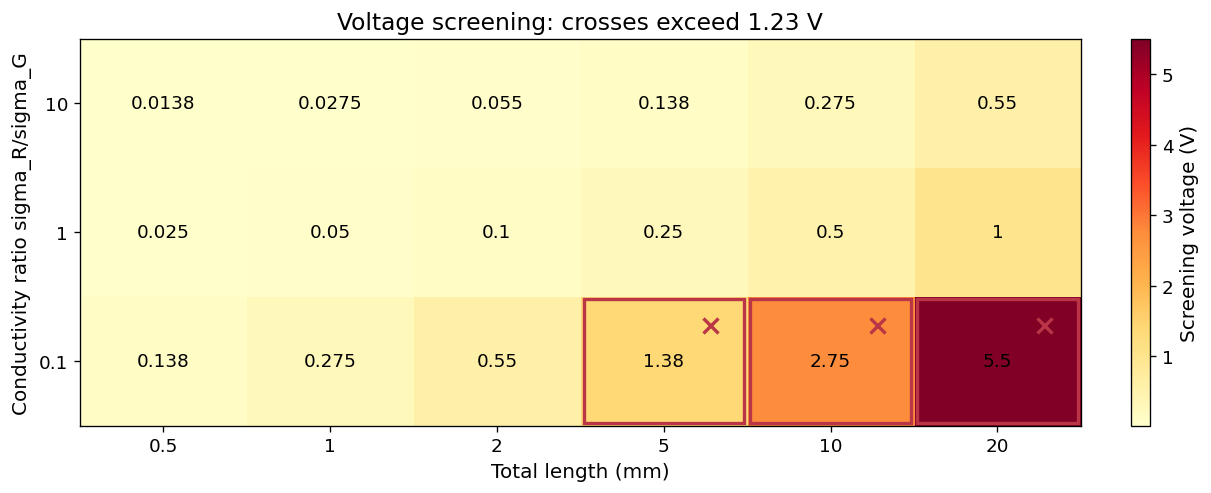

sigma_R/sigma_G,sigma_G_S_m,voltage_only_Lmax_mm
0.1,0.1,4.473
1,0.1,24.6
10,0.1,44.73


In [23]:
ratios = list(CONDUCTIVITY_RATIOS)
V = np.array([[(s.currents_A[0]/s.area_m2)*(L*1e-3)*(s.reservoir_fraction/(ratio*SIGMA_G_S_m)+(1-s.reservoir_fraction)/SIGMA_G_S_m)+EXTRA_VOLTAGE_V
               for L in LENGTHS_mm] for ratio in ratios])
fig,ax=plt.subplots(figsize=(10,4),constrained_layout=True)
im=ax.imshow(V,aspect='auto',origin='lower',cmap='YlOrRd')
ax.set_xticks(range(len(LENGTHS_mm)),labels=[f'{v:g}' for v in LENGTHS_mm])
ax.set_yticks(range(len(ratios)),labels=[f'{v:g}' for v in ratios])
ax.set(xlabel='Total length (mm)',ylabel='Conductivity ratio sigma_R/sigma_G',title=f'Voltage screening: crosses exceed {VOLTAGE_LIMIT_V:g} V')
for y in range(len(ratios)):
    for x in range(len(LENGTHS_mm)):
        ax.text(x,y,f'{V[y,x]:.3g}',ha='center',va='center',color='black')
        if V[y,x] > VOLTAGE_LIMIT_V: ax.add_patch(Rectangle((x-.48,y-.48),.96,.96,fill=False,edgecolor=RED,lw=2));ax.plot(x+.28,y+.28,'x',color=RED,ms=9,mew=2)
fig.colorbar(im,ax=ax,label='Screening voltage (V)');show_and_save()
voltage_bounds=[]
for ratio in ratios:
    denom=s.currents_A[0]*(s.reservoir_fraction/(ratio*SIGMA_G_S_m)+(1-s.reservoir_fraction)/SIGMA_G_S_m)
    Lmax=max(0,VOLTAGE_LIMIT_V-EXTRA_VOLTAGE_V)*s.area_m2/denom
    voltage_bounds.append({'sigma_R/sigma_G':ratio,'sigma_G_S_m':SIGMA_G_S_m,'voltage_only_Lmax_mm':Lmax*1000})
table(pd.DataFrame(voltage_bounds))
# Boundary checks: exactly 1.23 V passes, a value above it fails.
assert bool(with_criterion(pd.DataFrame([dict(df.iloc[0],voltage_V=VOLTAGE_LIMIT_V-EXTRA_VOLTAGE_V)])).voltage_pass.iloc[0])
assert not bool(with_criterion(pd.DataFrame([dict(df.iloc[0],voltage_V=VOLTAGE_LIMIT_V-EXTRA_VOLTAGE_V+1e-6)])).voltage_pass.iloc[0])

## 9. The trade-off after voltage screening
Grey crosses exceed the voltage criterion. Coloured points pass this criterion only. Their storage and delivery performance still need separate targets. Other inputs vary across points, so colour associations do not isolate a single-parameter effect.

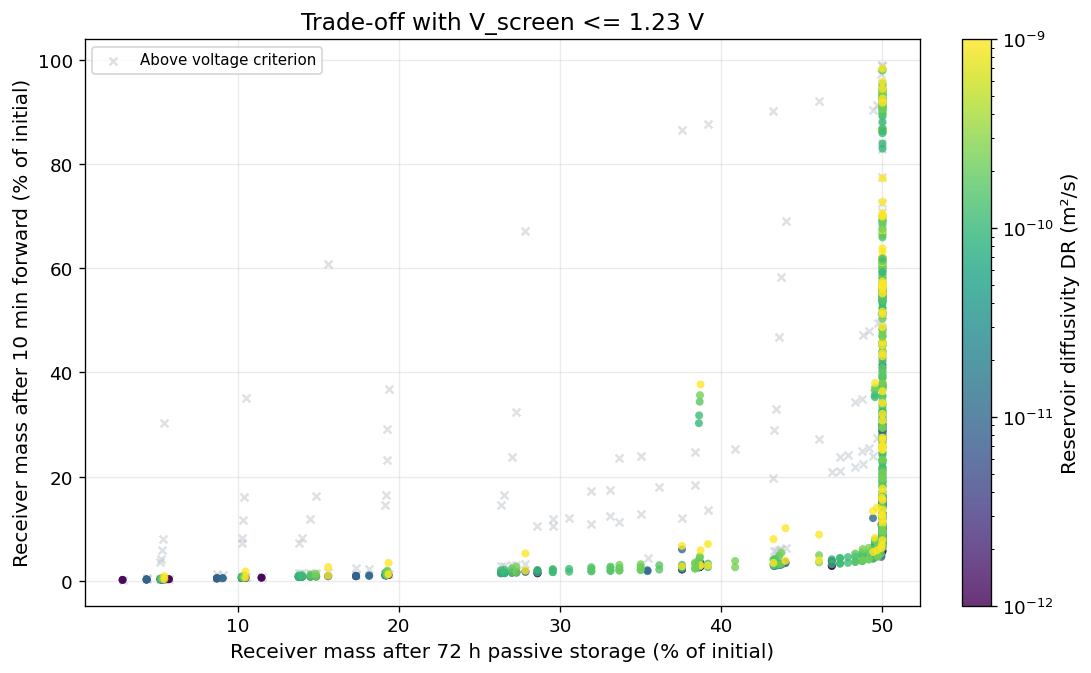

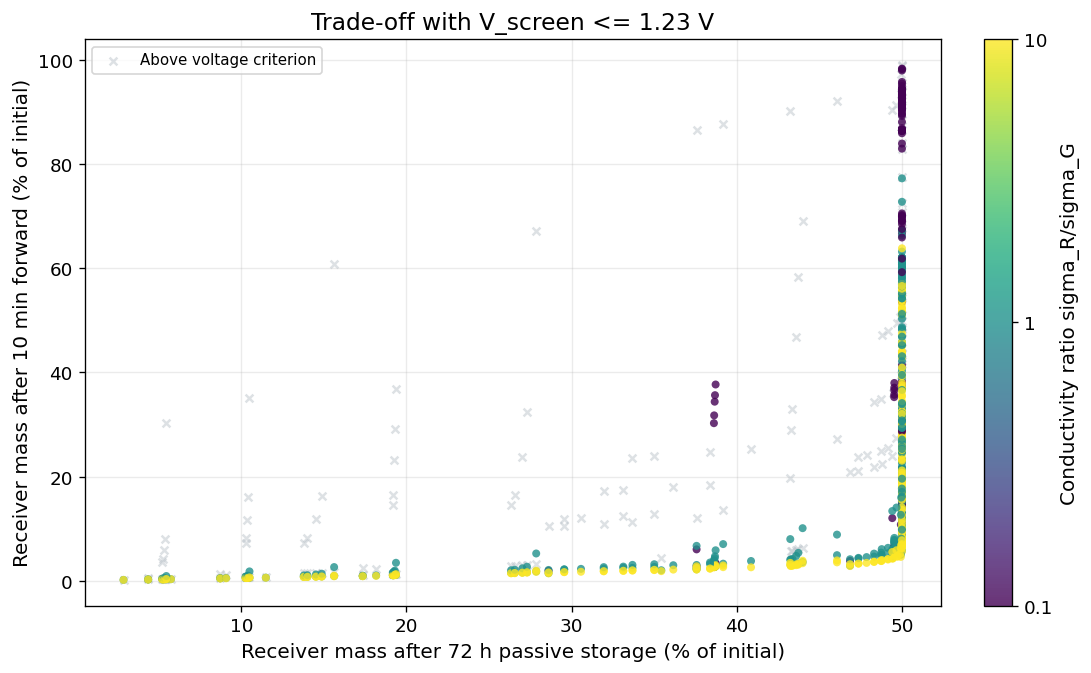

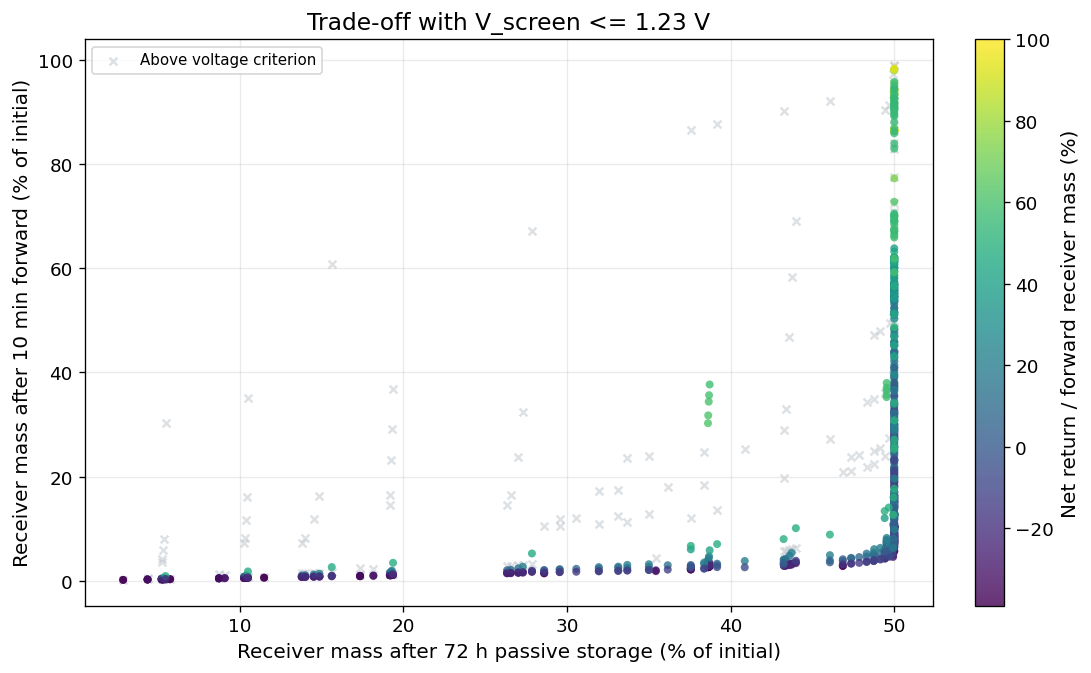

735 of 882 cases pass the voltage-only criterion.


In [24]:
for key,label in [('D_R_m2_s','Reservoir diffusivity DR (m²/s)'),('sigma_ratio','Conductivity ratio sigma_R/sigma_G'),('net_return_pct','Net return / forward receiver mass (%)')]:
    fig,ax=plt.subplots(figsize=(9,5.5),constrained_layout=True)
    excluded=df[~df.voltage_pass]
    ax.scatter(excluded.passive_72h_pct,excluded.forward_pct,c=GREY,marker='x',s=22,alpha=.5,label='Above voltage criterion')
    if not passing.empty:
        c=passing[key].to_numpy();norm=plt.Normalize(min(0,float(c.min())),100) if key=='net_return_pct' else LogNorm(max(float(c.min()),1e-30),float(c.max()) if c.max()>c.min() else c.min()*1.01)
        sc=ax.scatter(passing.passive_72h_pct,passing.forward_pct,c=c,norm=norm,cmap='viridis',s=23,alpha=.8,edgecolors='none')
        cb=fig.colorbar(sc,ax=ax,label=label)
        if key=='sigma_ratio':cb.set_ticks(CONDUCTIVITY_RATIOS);cb.set_ticklabels([f'{v:g}' for v in CONDUCTIVITY_RATIOS]);cb.minorticks_off()
    ax.set(xlabel='Receiver mass after 72 h passive storage (% of initial)',ylabel='Receiver mass after 10 min forward (% of initial)',title=f'Trade-off with V_screen <= {VOLTAGE_LIMIT_V:g} V')
    ax.grid(alpha=.25);ax.set_axisbelow(True)
    if len(excluded):ax.legend(fontsize=9)
    show_and_save()
print(f'{len(passing)} of {len(df)} cases pass the voltage-only criterion.')

## 10. Final design map: diffusivity–conductivity combinations

This contour map answers: **which combinations stay within the voltage criterion, and how much drug-proxy inventory do they transfer in 10 minutes?**

- Horizontal axis: common diffusivity **DR = DG = D**.
- Vertical axis: common conductivity **sigma_R = sigma_G = sigma**.
- Three panels: total lengths of 2, 5 and 10 mm.
- Colour and labelled contours: forward receiver inventory, as a percentage of initial loading.
- Red dashed boundary: `V_screen = 1.23 V`, using the editable criterion.
- Hatching: above the voltage criterion. Transport is not plotted for these excluded combinations.

This is an explicit two-dimensional slice with identical gels, not the complete independent-DR/DG/sigma_R/sigma_G design space. No arbitrary minimum transfer target is imposed. For a chosen target, such as 50%, look for a point satisfying both the voltage boundary and that transfer contour.

**The voltage boundary is independent of D in this model** because conductivity is prescribed independently of diffusivity. A physically attainable gel recipe may couple these properties.

Contour panel 1/3 complete
Contour panel 2/3 complete
Contour panel 3/3 complete


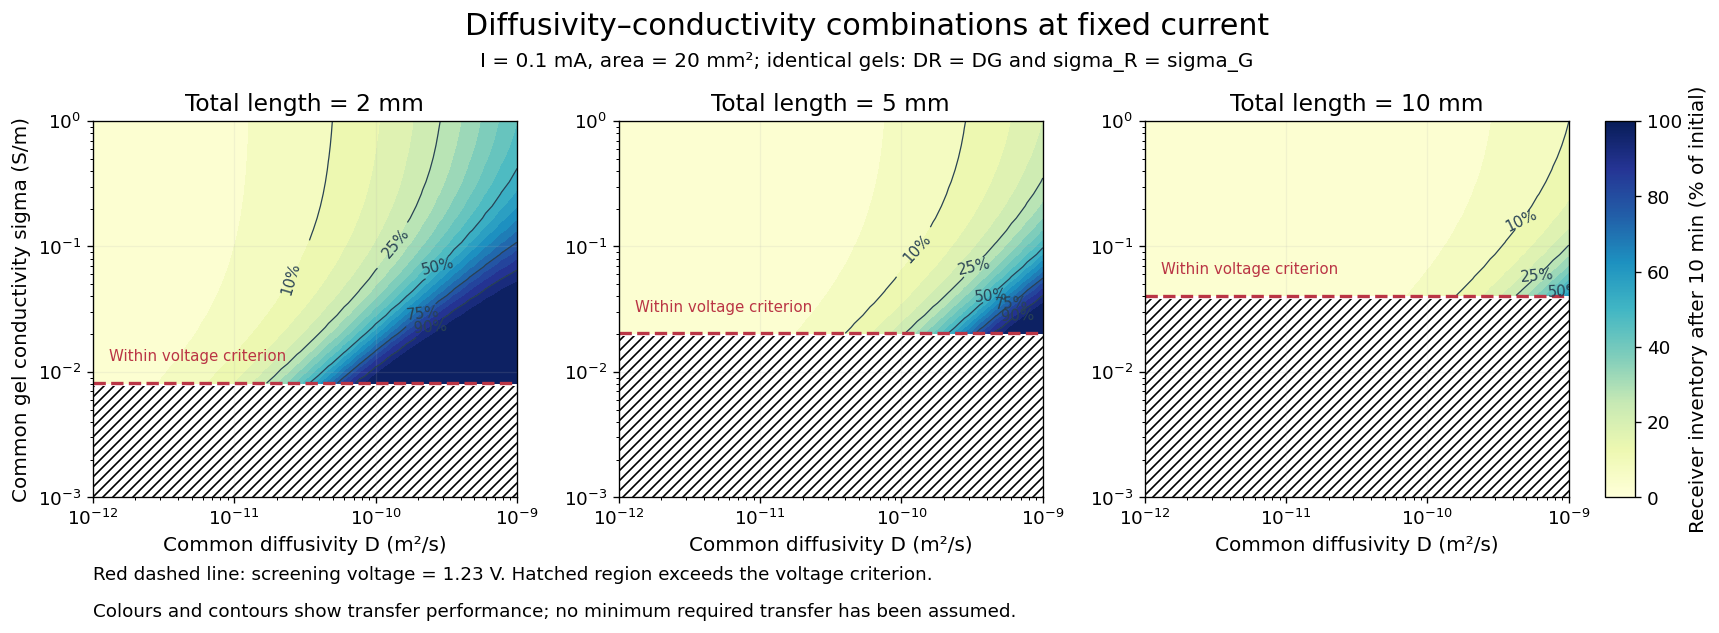

In [25]:
CONTOUR_CACHE_BASE64 = '...'

CONTOUR_LENGTHS_mm = [2.0, 5.0, 10.0]
CONTOUR_D_VALUES = np.geomspace(1e-12, 1e-9, 28)
CONTOUR_SIGMA_RANGE = (0.001, 1.0)
# Include each analytical voltage boundary as a grid row.
voltage_budget = VOLTAGE_LIMIT_V - EXTRA_VOLTAGE_V
boundary_sigmas = ([s.currents_A[0]*(L*1e-3)/(voltage_budget*s.area_m2)
                   for L in CONTOUR_LENGTHS_mm] if voltage_budget > 0 else [])
boundary_sigmas = [x for x in boundary_sigmas if CONTOUR_SIGMA_RANGE[0] <= x <= CONTOUR_SIGMA_RANGE[1]]
CONTOUR_SIGMAS = np.unique(np.r_[np.geomspace(*CONTOUR_SIGMA_RANGE, 32), boundary_sigmas])

cached_contours = np.load(io.BytesIO(base64.b64decode(CONTOUR_CACHE_BASE64)))
default = Settings()
contour_physics_match = all(np.allclose(np.asarray(getattr(s,k)), np.asarray(getattr(default,k)),
                                       rtol=1e-12, atol=0)
    for k in ['currents_A','area_m2','reservoir_fraction','loading_kg_m3','temperature_K',
              'charge','forward_s','dt_s','cells_per_gel'])
contour_grid_match = (np.array_equal(cached_contours['length_mm'], CONTOUR_LENGTHS_mm)
    and np.array_equal(cached_contours['diffusivity'], CONTOUR_D_VALUES)
    and len(cached_contours['conductivity']) == len(CONTOUR_SIGMAS)
    and np.allclose(cached_contours['conductivity'], CONTOUR_SIGMAS, rtol=1e-12, atol=0))
use_contour_cache = (contour_physics_match and contour_grid_match
    and VOLTAGE_LIMIT_V == 1.23 and EXTRA_VOLTAGE_V == 0 and not FORCE_RECOMPUTE)
if use_contour_cache:
    contour_transfer = cached_contours['forward_pct'].copy()
    print('Loaded embedded default contour results.')
else:
    contour_transfer = np.full((len(CONTOUR_LENGTHS_mm),len(CONTOUR_SIGMAS),len(CONTOUR_D_VALUES)),np.nan)
    for li,L in enumerate(CONTOUR_LENGTHS_mm):
        for si,sigma in enumerate(CONTOUR_SIGMAS):
            Vgel = s.currents_A[0]*(L*1e-3)/(sigma*s.area_m2)
            if Vgel+EXTRA_VOLTAGE_V > VOLTAGE_LIMIT_V*(1+1e-12): continue
            for di,D in enumerate(CONTOUR_D_VALUES):
                _,dx,d,conductivity = grid(L*1e-3,D,D,sigma,sigma,s)
                initial = np.r_[np.full(s.cells_per_gel,s.loading_kg_m3),np.zeros(s.cells_per_gel)]
                final,check,_ = evolve(initial,dx,d,conductivity,s.currents_A[0],s.forward_s,s.dt_s,s)
                assert check['worst_mass_error'] < s.mass_tolerance
                assert check['min_concentration'] >= -1e-8*s.loading_kg_m3
                contour_transfer[li,si,di] = 100*inventory(final,dx,s)[0]
        print(f'Contour panel {li+1}/{len(CONTOUR_LENGTHS_mm)} complete')

from matplotlib.cm import ScalarMappable
fig,axes = plt.subplots(1,len(CONTOUR_LENGTHS_mm),figsize=(15,5.7),squeeze=False)
axes=axes.ravel()
fig.subplots_adjust(left=.07,right=.89,bottom=.25,top=.80,wspace=.24)
for ax,L,Z in zip(axes,CONTOUR_LENGTHS_mm,contour_transfer):
    Vmap = s.currents_A[0]*(L*1e-3)/(CONTOUR_SIGMAS[:,None]*s.area_m2)*np.ones((1,len(CONTOUR_D_VALUES)))+EXTRA_VOLTAGE_V
    if np.isfinite(Z).any():
        ax.contourf(CONTOUR_D_VALUES,CONTOUR_SIGMAS,Z,levels=np.linspace(0,100,21),cmap='YlGnBu',vmin=0,vmax=100)
        levels=[v for v in [10,25,50,75,90] if np.nanmin(Z)<v<np.nanmax(Z)]
        if levels:
            cs=ax.contour(CONTOUR_D_VALUES,CONTOUR_SIGMAS,Z,levels=levels,colors='#294354',linewidths=.75)
            ax.clabel(cs,fmt='%g%%',fontsize=9,inline=True)
    ax.contourf(CONTOUR_D_VALUES,CONTOUR_SIGMAS,(Vmap>VOLTAGE_LIMIT_V*(1+1e-12)).astype(float),
                levels=[.5,1.5],colors='none',hatches=['////'])
    sigma_min = s.currents_A[0]*(L*1e-3)/(voltage_budget*s.area_m2) if voltage_budget>0 else np.inf
    if CONTOUR_SIGMAS.min() <= sigma_min <= CONTOUR_SIGMAS.max():
        ax.axhline(sigma_min,color=RED,lw=2,ls='--')
        ax.text(CONTOUR_D_VALUES.min()*1.3,sigma_min*1.5,'Within voltage criterion',fontsize=9,color=RED)
    ax.set(xscale='log',yscale='log',xlabel='Common diffusivity D (m²/s)',title=f'Total length = {L:g} mm')
    ax.grid(alpha=.15)
axes[0].set_ylabel('Common gel conductivity sigma (S/m)')
cax=fig.add_axes([.91,.25,.017,.55])
cb=fig.colorbar(ScalarMappable(norm=plt.Normalize(0,100),cmap='YlGnBu'),cax=cax)
cb.set_label(f'Receiver inventory after {s.forward_s/60:g} min (% of initial)')
fig.suptitle('Diffusivity–conductivity combinations at fixed current',fontsize=18,y=.96)
fig.text(.5,.88,f'I = {CURRENT_mA:g} mA, area = {AREA_mm2:g} mm²; identical gels: DR = DG and sigma_R = sigma_G',ha='center',fontsize=12)
fig.text(.07,.13,f'Red dashed line: screening voltage = {VOLTAGE_LIMIT_V:g} V. Hatched region exceeds the voltage criterion.',fontsize=11)
fig.text(.07,.075,'Colours and contours show transfer performance; no minimum required transfer has been assumed.',fontsize=11)
show_and_save()
if SAVE_OUTPUTS:
    np.savez_compressed(OUTPUT_DIR/'design_contour_data.npz',diffusivity=CONTOUR_D_VALUES,
                        conductivity=CONTOUR_SIGMAS,length_mm=CONTOUR_LENGTHS_mm,forward_pct=contour_transfer)


## 11. Final comparison: one input at a time
The five inputs below belong to three design categories: **diffusivity** (DR, DG), **conductivity** (sigma_R, sigma_G), and **length** (L). Each curve varies only its named input, with the other four fixed at the reference values. Red crosses mark points above the voltage criterion.

A common relative x-axis makes the changes comparable, but large parameter ranges remain nonlinear. The next cell therefore uses an identical ±10% perturbation for the final local ranking.

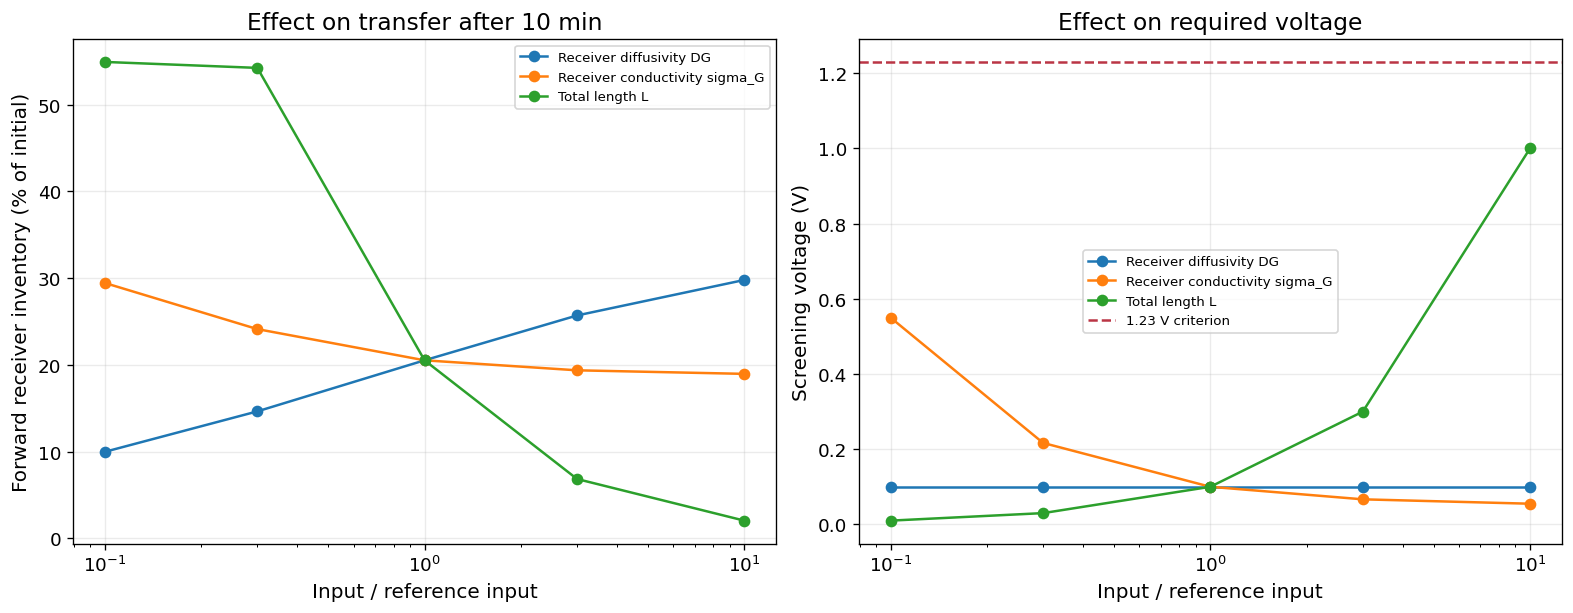

In [26]:
PARAMETERS = [
  #  ('Reservoir diffusivity DR','Diffusivity','DR',BASE_D_R),
    ('Receiver diffusivity DG','Diffusivity','DG',BASE_D_G),
  #  ('Reservoir conductivity sigma_R','Conductivity','sigma_R',BASE_SIGMA_R),
    ('Receiver conductivity sigma_G','Conductivity','sigma_G',BASE_SIGMA_G),
    ('Total length L','Length','L_mm',BASE_LENGTH_mm)]
multipliers=[0.1,0.3,1,3,10]
one_at_a_time=[]
for name,category,key,ref in PARAMETERS:
    for factor in multipliers:
        row=evaluate(**{key:ref*factor})
        row.update(parameter=name,category=category,multiplier=factor)
        one_at_a_time.append(row)
oat=pd.DataFrame(one_at_a_time)
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for name,_,_,_ in PARAMETERS:
    q=oat[oat.parameter==name]
    line,=axes[0].plot(q.multiplier,q.forward_pct,'-o',label=name)
    axes[1].plot(q.multiplier,q.V_screen_V,'-o',color=line.get_color(),label=name)
    for ax,value in [(axes[0],'forward_pct'),(axes[1],'V_screen_V')]:
        bad=q[~q.voltage_pass];ax.scatter(bad.multiplier,bad[value],marker='x',s=90,color=RED,zorder=5)
axes[0].set(ylabel='Forward receiver inventory (% of initial)',title='Effect on transfer after 10 min')
axes[1].set(ylabel='Screening voltage (V)',title='Effect on required voltage')
axes[1].axhline(VOLTAGE_LIMIT_V,color=RED,ls='--',label=f'{VOLTAGE_LIMIT_V:g} V criterion')
for ax in axes:ax.set_xscale('log');ax.set_xlabel('Input / reference input');ax.grid(alpha=.25)
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
show_and_save()

### Equal-percentage local sensitivities
For output y and input p, the dimensionless local sensitivity is estimated by
\[
S_{y,p}\approx\frac{\ln y[p(1+\epsilon)]-\ln y[p(1-\epsilon)]}{\ln(1+\epsilon)-\ln(1-\epsilon)}.
\]
A sensitivity of −0.5 means a small 1% increase in that input produces approximately a 0.5% decrease in the output near the reference. Signs show direction; absolute values compare local strength. This is **not a universal global ranking**. Passive-storage sensitivities can be nearly zero because the 72 h result is already near equilibrium.

Only perturbations that pass the voltage criterion are included in the displayed ranking. If a perturbation fails, its result is listed separately rather than silently used as a passing design.

Input,Category,Reference input,Both perturbations within voltage criterion,S_forward_fraction,S_passive_72h,S_voltage,S_absolute_mass
Receiver diffusivity DG,Diffusivity,1e-10,True,0.2416,-1.076e-09,0,0.2416
Receiver conductivity sigma_G,Conductivity,0.1,True,-0.08333,0,-0.5013,-0.08333
Total length L,Length,2,True,-0.9898,-1.207e-10,1,0.01015


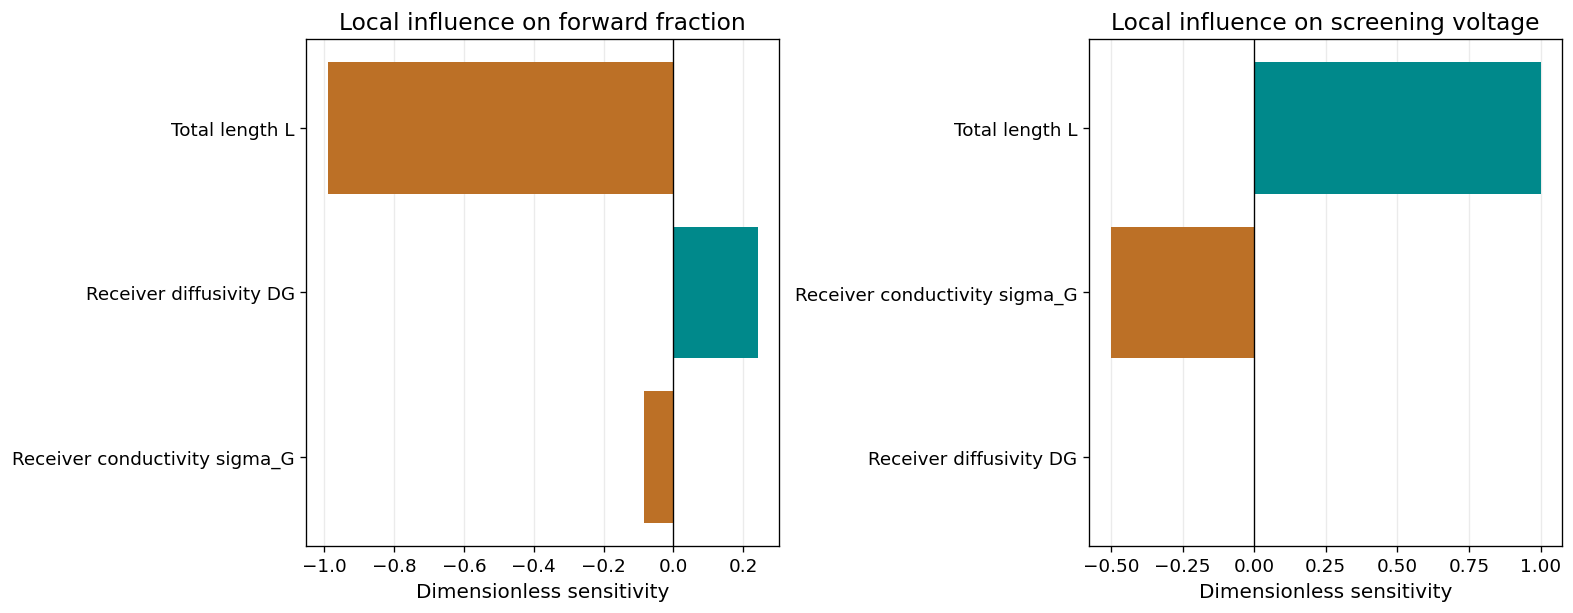

Largest absolute local effect on forward FRACTION: Total length L (sensitivity -0.990). This applies only near the selected reference.
Current remains fixed. Voltage criterion: 1.23 V; extra assumed voltage: 0.0 V.


In [27]:
sensitivity_rows=[]
for name,category,key,ref in PARAMETERS:
    minus=evaluate(**{key:ref*(1-LOCAL_CHANGE)})
    plus=evaluate(**{key:ref*(1+LOCAL_CHANGE)})
    entry={'Input':name,'Category':category,'Reference input':ref,
           'Both perturbations within voltage criterion':minus['voltage_pass'] and plus['voltage_pass']}
    for output,label in [('forward_fraction','S_forward_fraction'),('storage_leakage_fraction','S_passive_72h'),('V_screen_V','S_voltage'),('forward_mass_ug','S_absolute_mass')]:
        a,b=minus[output],plus[output]
        entry[label]=(np.log(b)-np.log(a))/(np.log(1+LOCAL_CHANGE)-np.log(1-LOCAL_CHANGE)) if a>0 and b>0 else np.nan
    sensitivity_rows.append(entry)
sensitivity=pd.DataFrame(sensitivity_rows)
valid_sensitivity=sensitivity[sensitivity['Both perturbations within voltage criterion']].copy()
table(sensitivity)
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,key,title in [(axes[0],'S_forward_fraction','Local influence on forward fraction'),(axes[1],'S_voltage','Local influence on screening voltage')]:
    ordered=valid_sensitivity.sort_values(key,key=lambda q:q.abs())
    ax.barh(ordered.Input,ordered[key],color=[TEAL if x>=0 else ORANGE for x in ordered[key]])
    ax.axvline(0,color='black',lw=.8);ax.set(xlabel='Dimensionless sensitivity',title=title);ax.grid(axis='x',alpha=.25);ax.set_axisbelow(True)
show_and_save()
if len(valid_sensitivity):
    strongest=valid_sensitivity.iloc[np.nanargmax(valid_sensitivity.S_forward_fraction.abs())]
    print('Largest absolute local effect on forward FRACTION:',strongest.Input,
          f'(sensitivity {strongest.S_forward_fraction:.3f}). This applies only near the selected reference.')
print('Current remains fixed. Voltage criterion:',VOLTAGE_LIMIT_V,'V; extra assumed voltage:',EXTRA_VOLTAGE_V,'V.')

### What the comparison means

| Design category | Transport effect in this model | Voltage implication |
|---|---|---|
| Diffusivity | Changes passive spreading and electrical mobility in each gel | No direct voltage effect when conductivity is held fixed |
| Conductivity | Changes local electric fields at imposed current | Higher conductivity reduces the gel voltage requirement |
| Length | Changes transport distance and initial inventory | Required gel voltage grows linearly with length at fixed compartment fractions |

**Design decision:** use the voltage filter first, then compare forward transfer, passive storage and reversal among the remaining cases. Passing 1.23 V is necessary for this chosen screen but does not prove electrochemical stability, an adequate dose or acceptable storage. No delivery/retention targets have been invented.

The effect on absolute mass can differ from the effect on fraction because reservoir inventory changes with length. Diffusivity and conductivity are independent numerical inputs here; a real formulation may couple them.

The final cell exports named datasets and settings automatically when `SAVE_OUTPUTS = True`.

In [28]:
if SAVE_OUTPUTS:
    df.to_csv(OUTPUT_DIR/'all_cases_with_voltage_criterion.csv',index=False)
    passing.to_csv(OUTPUT_DIR/'voltage_passing_candidates.csv',index=False)
    sensitivity.to_csv(OUTPUT_DIR/'local_parameter_influence.csv',index=False)
    oat.to_csv(OUTPUT_DIR/'one_at_a_time_comparison.csv',index=False)
    length_df.to_csv(OUTPUT_DIR/'length_comparison.csv',index=False)
    diff_df.to_csv(OUTPUT_DIR/'diffusivity_comparison.csv',index=False)
    reservoir_sigma.to_csv(OUTPUT_DIR/'reservoir_conductivity_comparison.csv',index=False)
    common_sigma.to_csv(OUTPUT_DIR/'common_conductivity_comparison.csv',index=False)
    (OUTPUT_DIR/'settings.json').write_text(json.dumps({
        'model':asdict(s),'voltage_limit_V':VOLTAGE_LIMIT_V,'extra_voltage_V':EXTRA_VOLTAGE_V,
        'baseline':{'length_mm':BASE_LENGTH_mm,'D_R':BASE_D_R,'D_G':BASE_D_G,
                    'sigma_R':BASE_SIGMA_R,'sigma_G':BASE_SIGMA_G},
        'local_change':LOCAL_CHANGE},indent=2),encoding='utf-8')
    print('Saved figures (PNG/PDF), tables (CSV/HTML), datasets, contour data and settings to:')
    print(OUTPUT_DIR.resolve())
    print('Save this notebook in Jupyter to retain changed code and displayed outputs.')
else:
    print('Automatic export disabled. Results remain in memory and notebook outputs.')


Saved figures (PNG/PDF), tables (CSV/HTML), datasets, contour data and settings to:
/Users/parissaalavi/Downloads/Molesense_presentation/gel_transport_outputs/20261028_153508_333202
Save this notebook in Jupyter to retain changed code and displayed outputs.
